<h1><center>Introduccion PySpark</center></h1>

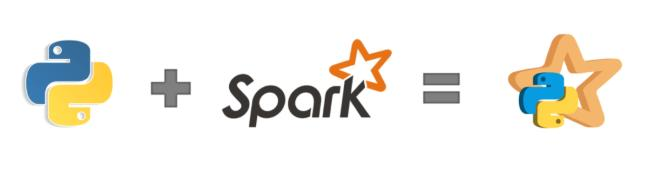

## ⚡ ¿Qué es Spark y por qué PySpark?

Si trabajas con Big Data, Spark aparece muy rápido en el camino.
Apache Spark se define como un **motor de analítica distribuido y muy rápido**.

El problema no es Python.
El problema es intentar procesar **datos muy grandes en un solo ordenador**.

Cuando los datos crecen:
- pandas deja de escalar
- la memoria se convierte en un cuello de botella
- los tiempos de ejecución se disparan

## 💡 La idea clave de Spark

En lugar de mover los datos a tu código,
**Spark mueve el código a donde están los datos**.

Los datos están distribuidos & El procesamiento también.

Resultado:
- menos movimiento de datos
- menos problemas de memoria
- mejores tiempos de ejecución


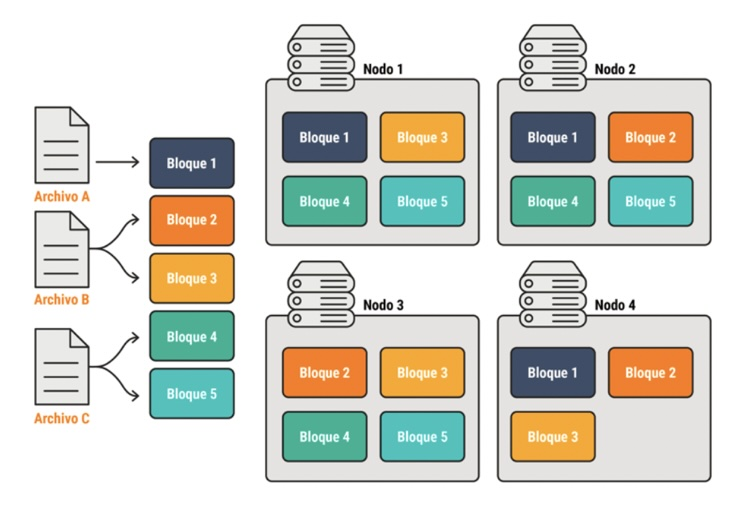

## ⚡ ¿Qué es PySpark?

PySpark es la **API de Spark para Python**.

Permite:
- análisis de datos a gran escala
- procesos ETL
- pipelines de machine learning
- todo de forma distribuida

Si ya sabes Python (y pandas),
**la curva de aprendizaje es suave**.

## ⚔️  PySpark vs Scala

Spark también se puede usar con Scala.

- Scala es más rápido (JVM, lenguaje nativo)
- PySpark es más fácil de aprender
- PySpark se usa mucho en data science y ML

**PySpark es la puerta de entrada más común a Spark**.


## ▶️ Cómo ejecuta Spark tu código

En Spark hay dos conceptos clave:

- Transformations:
  operaciones que crean un nuevo DataFrame
  (filter, groupBy, select, map...)

- Actions:
  operaciones que fuerzan la ejecución
  (show, count, collect...)

## 🦥 Lazy Evaluation

Spark no ejecuta nada inmediatamente.

- Las transformaciones se acumulan
- Spark construye un plan de ejecución
- El cálculo solo se lanza cuando hay una acción

Esto permite:
- optimizar el plan
- mejorar el rendimiento
- escalar a grandes volúmenes de datos

🚨 No vamos a ver si tenemos un error hasta que no hagamos un acción

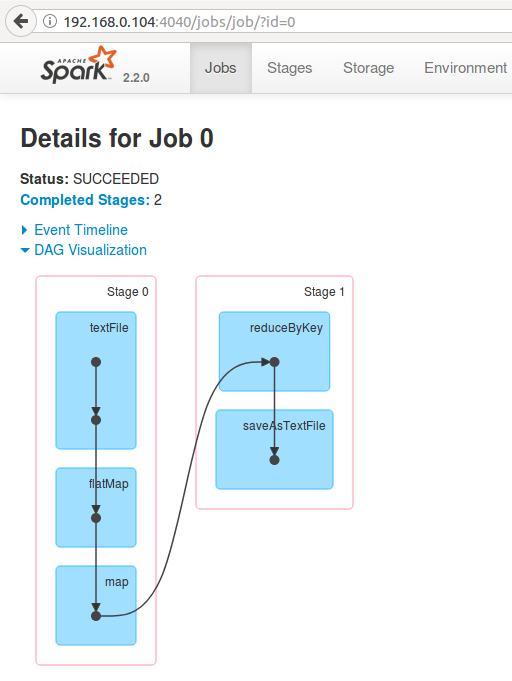

Extra: Spark UI https://ianwhitestone.work/spark-web-ui/

## 🌐 Ecosistema Spark

Spark se compone de varios módulos:

- Spark SQL → DataFrames y SQL
- Spark Streaming → datos en tiempo real
- Spark MLlib → machine learning
- Spark GraphX → grafos

En este curso nos centraremos principalmente en **Spark SQL y PySpark DataFrames**.


### Preflight local (Java + entorno)

Antes de crear la `SparkSession`, verifica que Java esta disponible en el `PATH`.


In [1]:
import os, shutil, subprocess

os.environ["JAVA_HOME"] = "/Users/beatrizsuch/java/temurin-17/Contents/Home"
os.environ["PATH"] = f'{os.environ["JAVA_HOME"]}/bin:' + os.environ["PATH"]

print("JAVA_HOME =", os.environ.get("JAVA_HOME"))
print("java path =", shutil.which("java"))
subprocess.run(["java", "-version"], check=True)

JAVA_HOME = /Users/beatrizsuch/java/temurin-17/Contents/Home
java path = /Users/beatrizsuch/java/temurin-17/Contents/Home/bin/java


openjdk version "17.0.21" 2026-10-20
OpenJDK Runtime Environment Temurin-17.0.21+9 (build 17.0.21+9)
OpenJDK 64-Bit Server VM Temurin-17.0.21+9 (build 17.0.21+9, mixed mode, sharing)


CompletedProcess(args=['java', '-version'], returncode=0)

In [2]:
# Crear SparkSession para entorno local
import os, sys, subprocess, platform
from pyspark.sql import SparkSession

if not os.environ.get('JAVA_HOME') and platform.system() == 'Darwin':
    try:
        os.environ['JAVA_HOME'] = subprocess.check_output(['/usr/libexec/java_home', '-v', '17'], text=True).strip()
    except Exception:
        pass

if os.environ.get('JAVA_HOME'):
    os.environ['PATH'] = f"{os.environ['JAVA_HOME']}/bin:" + os.environ.get('PATH', '')

# Evita mismatch entre Python driver y workers en Spark local
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
os.environ['PYSPARK_PYTHON'] = sys.executable

In [3]:
spark = (
    SparkSession.builder
    .appName('ClaseSpark-Local')
    .master('local[*]')
    .config('spark.sql.shuffle.partitions', '8')
    .config('spark.pyspark.driver.python', sys.executable)
    .config('spark.pyspark.python', sys.executable)
    .getOrCreate()
)

spark.sparkContext.setLogLevel('WARN')

print('Python executable:', sys.executable)
print('Spark version:', spark.version)
print('Master:', spark.sparkContext.master)
print('Default parallelism:', spark.sparkContext.defaultParallelism)
spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/14 17:25:34 WARN Utils: Your hostname, MacBook-Pro-de-Beatriz.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.68 instead (on interface en0)
26/11/14 17:25:34 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 17:25:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/14 17:25:35 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Python executable: /Users/beatrizsuch/spark_project/.venv/bin/python
Spark version: 4.3.0
Master: local[*]
Default parallelism: 8


<a id='loading-the-dataset'></a>
### Cargar Dataset

In [4]:
# Descargar dataset (si no existe) en /data del proyecto y usar ruta estable
from pathlib import Path
from urllib.request import urlretrieve

project_root = Path.cwd()
if not (project_root / 'pyproject.toml').exists() and (project_root.parent / 'pyproject.toml').exists():
    project_root = project_root.parent

data_dir = project_root / 'data'
data_dir.mkdir(parents=True, exist_ok=True)
url = 'https://jacobceles.github.io/knowledge_repo/colab_and_pyspark/cars.csv'
data_csv = data_dir / 'cars.csv'

if not data_csv.exists():
    urlretrieve(url, data_csv.as_posix())
    print(f'Dataset descargado en: {data_csv.resolve()}')
else:
    print(f'Dataset ya disponible en: {data_csv.resolve()}')


Dataset ya disponible en: /Users/beatrizsuch/spark_project/data/cars.csv


# Operaciones Básica con Spark Dataframe - Pyspark

In [5]:
# Cargar datos desde un CSV a un DataFrame
# header=True indica que la primera fila es el encabezado
# sep=';' indica que las columnas están separadas por ';'
df = spark.read.csv(str(data_csv), header=True, sep=';')
df.show(5)


+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


El comando anterior carga nuestros datos en un DataFrame (DF).  
Un DataFrame es una estructura de datos bidimensional etiquetada, con columnas que pueden tener diferentes tipos de datos.


<a id='viewing-the-dataframe'></a>
### Visualizando el DataFrame


Existen varias formas de visualizar tu DataFrame (DF) en PySpark:

1. `df.take(5)` devuelve una lista con cinco objetos *Row*.  
2. `df.collect()` obtiene todos los datos de todo el DataFrame. Ten mucho cuidado al usarlo, porque si tienes un conjunto de datos muy grande, puedes colapsar el nodo *driver*.  
3. `df.show()` es el método más común para ver un DataFrame. Se le pueden pasar algunos parámetros, como el número de filas y la truncación. Por ejemplo, `df.show(5, False)` o `df.show(5, truncate=False)` mostrará todos los datos sin truncarlos.  
4. `df.limit(5)` **devuelve un nuevo DataFrame** tomando las primeras *n* filas. Como Spark es distribuido por naturaleza, no hay garantía de que `df.limit()` devuelva los mismos resultados cada vez.

Veamos algunos de estos métodos en acción a continuación:


In [6]:
df.show(5, truncate=False)

+-------------------------+----+---------+------------+----------+------+------------+-----+------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+-------------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |
|Plymouth Satellite       |18.0|8        |318.0       |150.0     |3436. |11.0        |70   |US    |
|AMC Rebel SST            |16.0|8        |304.0       |150.0     |3433. |12.0        |70   |US    |
|Ford Torino              |17.0|8        |302.0       |140.0     |3449. |10.5        |70   |US    |
+-------------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


In [7]:
df.limit(5)

DataFrame[Car: string, MPG: string, Cylinders: string, Displacement: string, Horsepower: string, Weight: string, Acceleration: string, Model: string, Origin: string]

In [8]:
df.take(5)

[Row(Car='Chevrolet Chevelle Malibu', MPG='18.0', Cylinders='8', Displacement='307.0', Horsepower='130.0', Weight='3504.', Acceleration='12.0', Model='70', Origin='US'),
 Row(Car='Buick Skylark 320', MPG='15.0', Cylinders='8', Displacement='350.0', Horsepower='165.0', Weight='3693.', Acceleration='11.5', Model='70', Origin='US'),
 Row(Car='Plymouth Satellite', MPG='18.0', Cylinders='8', Displacement='318.0', Horsepower='150.0', Weight='3436.', Acceleration='11.0', Model='70', Origin='US'),
 Row(Car='AMC Rebel SST', MPG='16.0', Cylinders='8', Displacement='304.0', Horsepower='150.0', Weight='3433.', Acceleration='12.0', Model='70', Origin='US'),
 Row(Car='Ford Torino', MPG='17.0', Cylinders='8', Displacement='302.0', Horsepower='140.0', Weight='3449.', Acceleration='10.5', Model='70', Origin='US')]

In [9]:
df.limit(5).collect()[0][0]

'Chevrolet Chevelle Malibu'

<a id='visualizar-columnas-dataframe'></a>
### Visualizar columnas

In [10]:
df.columns

['Car',
 'MPG',
 'Cylinders',
 'Displacement',
 'Horsepower',
 'Weight',
 'Acceleration',
 'Model',
 'Origin']

<a id='dataframe-schema'></a>
### Esquema del dataframe

Existen dos métodos comúnmente utilizados para ver los tipos de datos de un DataFrame:


In [11]:
df.dtypes

[('Car', 'string'),
 ('MPG', 'string'),
 ('Cylinders', 'string'),
 ('Displacement', 'string'),
 ('Horsepower', 'string'),
 ('Weight', 'string'),
 ('Acceleration', 'string'),
 ('Model', 'string'),
 ('Origin', 'string')]

In [12]:
df.printSchema()

root
 |-- Car: string (nullable = true)
 |-- MPG: string (nullable = true)
 |-- Cylinders: string (nullable = true)
 |-- Displacement: string (nullable = true)
 |-- Horsepower: string (nullable = true)
 |-- Weight: string (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Model: string (nullable = true)
 |-- Origin: string (nullable = true)



<a id='implicit-schema-inference'></a>
#### Inferring Schema Implicitly

Podemos usar el parámetro `inferSchema=True` para inferir automáticamente el esquema de entrada al cargar los datos. Un ejemplo se muestra a continuación:


In [13]:
df.limit(5).show()

+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+



In [14]:
# Cargar datos desde un CSV a un DataFrame
# header=True indica que la primera fila es el encabezado
# sep=';' indica que las columnas están separadas por ';'
df = spark.read.csv(str(data_csv), header=True, sep=';')
df.show(5)


+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


Spark ha inferido automáticamente el tipo de dato, incluso con la precisión correcta para el tipo decimal.  
Un problema que puede surgir es que, a veces, al leer múltiples archivos con esquemas diferentes, la inferencia automática puede generar valores *null* en algunas columnas.  
Por ello, veamos también cómo definir los esquemas de forma explícita.


<a id='schema-explicito'></a>
#### Definir explicitamente el Schema

In [15]:
from pyspark.sql.types import *
df.columns

['Car',
 'MPG',
 'Cylinders',
 'Displacement',
 'Horsepower',
 'Weight',
 'Acceleration',
 'Model',
 'Origin']

In [16]:
# Genero una lista con el formato: nombre_columna, tipo_del_dato
labels = [
     ('Car',StringType()),
     ('MPG',DoubleType()),
     ('Cylinders',IntegerType()),
     ('Displacement',DoubleType()),
     ('Horsepower',DoubleType()),
     ('Weight',DoubleType()),
     ('Acceleration',DoubleType()),
     ('Model',IntegerType()),
     ('Origin',StringType())
]

In [17]:
# Creo el Schema que se indicará en la lectura del csv
schema = StructType([StructField (x[0], x[1], True) for x in labels])
schema

StructType([StructField('Car', StringType(), True), StructField('MPG', DoubleType(), True), StructField('Cylinders', IntegerType(), True), StructField('Displacement', DoubleType(), True), StructField('Horsepower', DoubleType(), True), StructField('Weight', DoubleType(), True), StructField('Acceleration', DoubleType(), True), StructField('Model', IntegerType(), True), StructField('Origin', StringType(), True)])

In [18]:
# Cargar datos desde un CSV a un DataFrame
# header=True indica que la primera fila es el encabezado
# sep=';' indica que las columnas están separadas por ';'
df = spark.read.csv(str(data_csv), header=True, sep=';')
df.show(5)


+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


In [19]:
df.show(truncate=False)

+--------------------------------+----+---------+------------+----------+------+------------+-----+------+
|Car                             |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevelle Malibu       |18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |
|Buick Skylark 320               |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |
|Plymouth Satellite              |18.0|8        |318.0       |150.0     |3436. |11.0        |70   |US    |
|AMC Rebel SST                   |16.0|8        |304.0       |150.0     |3433. |12.0        |70   |US    |
|Ford Torino                     |17.0|8        |302.0       |140.0     |3449. |10.5        |70   |US    |
|Ford Galaxie 500                |15.0|8        |429.0       |198.0     |4341. |10.0        |70   |US    |
|Chevrolet Impala                |14.

<a id='dataframe-operations-on-columns'></a>
## Operaciones en columnas de un DataFrame


En esta sección revisaremos:

1. Selección de columnas  
2. Selección de múltiples columnas  
3. Agregar nuevas columnas  
4. Renombrar columnas  
5. Agrupar por columnas  
6. Eliminar columnas



<a id='selecting-columns'></a>
### Selección de columnas


Existen varias formas de realizar una selección (*select*) en PySpark. A continuación se explica cómo difieren y cómo usar cada una:


In [20]:
# 1er metodo
df.select(df.Car).show(truncate=False)

+--------------------------------+
|Car                             |
+--------------------------------+
|Chevrolet Chevelle Malibu       |
|Buick Skylark 320               |
|Plymouth Satellite              |
|AMC Rebel SST                   |
|Ford Torino                     |
|Ford Galaxie 500                |
|Chevrolet Impala                |
|Plymouth Fury iii               |
|Pontiac Catalina                |
|AMC Ambassador DPL              |
|Citroen DS-21 Pallas            |
|Chevrolet Chevelle Concours (sw)|
|Ford Torino (sw)                |
|Plymouth Satellite (sw)         |
|AMC Rebel SST (sw)              |
|Dodge Challenger SE             |
|Plymouth 'Cuda 340              |
|Ford Mustang Boss 302           |
|Chevrolet Monte Carlo           |
|Buick Estate Wagon (sw)         |
+--------------------------------+
only showing top 20 rows


In [21]:
df

DataFrame[Car: string, MPG: string, Cylinders: string, Displacement: string, Horsepower: string, Weight: string, Acceleration: string, Model: string, Origin: string]

In [22]:
df.select('Car').show(truncate=False)

+--------------------------------+
|Car                             |
+--------------------------------+
|Chevrolet Chevelle Malibu       |
|Buick Skylark 320               |
|Plymouth Satellite              |
|AMC Rebel SST                   |
|Ford Torino                     |
|Ford Galaxie 500                |
|Chevrolet Impala                |
|Plymouth Fury iii               |
|Pontiac Catalina                |
|AMC Ambassador DPL              |
|Citroen DS-21 Pallas            |
|Chevrolet Chevelle Concours (sw)|
|Ford Torino (sw)                |
|Plymouth Satellite (sw)         |
|AMC Rebel SST (sw)              |
|Dodge Challenger SE             |
|Plymouth 'Cuda 340              |
|Ford Mustang Boss 302           |
|Chevrolet Monte Carlo           |
|Buick Estate Wagon (sw)         |
+--------------------------------+
only showing top 20 rows


In [23]:
# 2º metodo

# No distingue entre mayusculas y minusculas
df.select(df['car']).show(truncate=False)

+--------------------------------+
|car                             |
+--------------------------------+
|Chevrolet Chevelle Malibu       |
|Buick Skylark 320               |
|Plymouth Satellite              |
|AMC Rebel SST                   |
|Ford Torino                     |
|Ford Galaxie 500                |
|Chevrolet Impala                |
|Plymouth Fury iii               |
|Pontiac Catalina                |
|AMC Ambassador DPL              |
|Citroen DS-21 Pallas            |
|Chevrolet Chevelle Concours (sw)|
|Ford Torino (sw)                |
|Plymouth Satellite (sw)         |
|AMC Rebel SST (sw)              |
|Dodge Challenger SE             |
|Plymouth 'Cuda 340              |
|Ford Mustang Boss 302           |
|Chevrolet Monte Carlo           |
|Buick Estate Wagon (sw)         |
+--------------------------------+
only showing top 20 rows


In [24]:
# 3º metodo

from pyspark.sql.functions import col
df.select(col('car')).show(truncate=False)

+--------------------------------+
|car                             |
+--------------------------------+
|Chevrolet Chevelle Malibu       |
|Buick Skylark 320               |
|Plymouth Satellite              |
|AMC Rebel SST                   |
|Ford Torino                     |
|Ford Galaxie 500                |
|Chevrolet Impala                |
|Plymouth Fury iii               |
|Pontiac Catalina                |
|AMC Ambassador DPL              |
|Citroen DS-21 Pallas            |
|Chevrolet Chevelle Concours (sw)|
|Ford Torino (sw)                |
|Plymouth Satellite (sw)         |
|AMC Rebel SST (sw)              |
|Dodge Challenger SE             |
|Plymouth 'Cuda 340              |
|Ford Mustang Boss 302           |
|Chevrolet Monte Carlo           |
|Buick Estate Wagon (sw)         |
+--------------------------------+
only showing top 20 rows


In [25]:
import pyspark.sql.functions as sf
df.select(sf.col('car')).show(truncate=False)

+--------------------------------+
|car                             |
+--------------------------------+
|Chevrolet Chevelle Malibu       |
|Buick Skylark 320               |
|Plymouth Satellite              |
|AMC Rebel SST                   |
|Ford Torino                     |
|Ford Galaxie 500                |
|Chevrolet Impala                |
|Plymouth Fury iii               |
|Pontiac Catalina                |
|AMC Ambassador DPL              |
|Citroen DS-21 Pallas            |
|Chevrolet Chevelle Concours (sw)|
|Ford Torino (sw)                |
|Plymouth Satellite (sw)         |
|AMC Rebel SST (sw)              |
|Dodge Challenger SE             |
|Plymouth 'Cuda 340              |
|Ford Mustang Boss 302           |
|Chevrolet Monte Carlo           |
|Buick Estate Wagon (sw)         |
+--------------------------------+
only showing top 20 rows


<a id='seleccion-columnas-multiples'></a>
### Selección de múltiples columnas


In [26]:
# 1er método
df.select(df.Car, df.Cylinders).show(truncate=False)

+--------------------------------+---------+
|Car                             |Cylinders|
+--------------------------------+---------+
|Chevrolet Chevelle Malibu       |8        |
|Buick Skylark 320               |8        |
|Plymouth Satellite              |8        |
|AMC Rebel SST                   |8        |
|Ford Torino                     |8        |
|Ford Galaxie 500                |8        |
|Chevrolet Impala                |8        |
|Plymouth Fury iii               |8        |
|Pontiac Catalina                |8        |
|AMC Ambassador DPL              |8        |
|Citroen DS-21 Pallas            |4        |
|Chevrolet Chevelle Concours (sw)|8        |
|Ford Torino (sw)                |8        |
|Plymouth Satellite (sw)         |8        |
|AMC Rebel SST (sw)              |8        |
|Dodge Challenger SE             |8        |
|Plymouth 'Cuda 340              |8        |
|Ford Mustang Boss 302           |8        |
|Chevrolet Monte Carlo           |8        |
|Buick Est


[Stage 16:>                                                         (0 + 1) / 1]



In [27]:
# 2º metodo

df.select(df['car'],df['cylinders']).show(truncate=False)

+--------------------------------+---------+
|car                             |cylinders|
+--------------------------------+---------+
|Chevrolet Chevelle Malibu       |8        |
|Buick Skylark 320               |8        |
|Plymouth Satellite              |8        |
|AMC Rebel SST                   |8        |
|Ford Torino                     |8        |
|Ford Galaxie 500                |8        |
|Chevrolet Impala                |8        |
|Plymouth Fury iii               |8        |
|Pontiac Catalina                |8        |
|AMC Ambassador DPL              |8        |
|Citroen DS-21 Pallas            |4        |
|Chevrolet Chevelle Concours (sw)|8        |
|Ford Torino (sw)                |8        |
|Plymouth Satellite (sw)         |8        |
|AMC Rebel SST (sw)              |8        |
|Dodge Challenger SE             |8        |
|Plymouth 'Cuda 340              |8        |
|Ford Mustang Boss 302           |8        |
|Chevrolet Monte Carlo           |8        |
|Buick Est

In [28]:
# 3er método
from pyspark.sql.functions import col
df.select(col('car'),col('cylinders')).show(truncate=False)

+--------------------------------+---------+
|car                             |cylinders|
+--------------------------------+---------+
|Chevrolet Chevelle Malibu       |8        |
|Buick Skylark 320               |8        |
|Plymouth Satellite              |8        |
|AMC Rebel SST                   |8        |
|Ford Torino                     |8        |
|Ford Galaxie 500                |8        |
|Chevrolet Impala                |8        |
|Plymouth Fury iii               |8        |
|Pontiac Catalina                |8        |
|AMC Ambassador DPL              |8        |
|Citroen DS-21 Pallas            |4        |
|Chevrolet Chevelle Concours (sw)|8        |
|Ford Torino (sw)                |8        |
|Plymouth Satellite (sw)         |8        |
|AMC Rebel SST (sw)              |8        |
|Dodge Challenger SE             |8        |
|Plymouth 'Cuda 340              |8        |
|Ford Mustang Boss 302           |8        |
|Chevrolet Monte Carlo           |8        |
|Buick Est

<a id='anadir-columnas'></a>
### Añadir nuevas columnas

Aquí revisaremos tres casos:

1. Agregar una nueva columna  
2. Agregar múltiples columnas  
3. Derivar una nueva columna a partir de una existente


In [29]:
# CASO 1: Agregar una nueva columna
# Vamos a agregar una nueva columna llamada 'first_column' al final
from pyspark.sql.functions import lit

df = df.withColumn('primera_nueva_columna', lit(1))
# lit significa "literal". Llena la fila con el valor literal dado.
# Al agregar datos estáticos o valores constantes, es buena práctica usarlo.

df.show(5, truncate=False)


+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|primera_nueva_columna|
+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |1                    |
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |1                    |
|Plymouth Satellite       |18.0|8        |318.0       |150.0     |3436. |11.0        |70   |US    |1                    |
|AMC Rebel SST            |16.0|8        |304.0       |150.0     |3433. |12.0        |70   |US    |1                    |
|Ford Torino              |17.0|8        |302.0       |140.0     |3449. |10.5        |70   |US    |1                    |
+-----------------------

In [30]:
# CASO 2: Agregar múltiples columnas
# Vamos a agregar dos nuevas columnas llamadas 'segunda_columna_nueva' y 'tercera_columna_nueva' al final
df = df.withColumn('segunda_columna_nueva', lit(2)) \
       .withColumn('tercera_columna_nueva', lit('Tercera Columna'))
# lit significa "literal". Llena la fila con el valor literal dado.
# Al agregar datos estáticos o valores constantes, es buena práctica usarlo.

df.show(5, truncate=False)


+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|primera_nueva_columna|segunda_columna_nueva|tercera_columna_nueva|
+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |1                    |2                    |Tercera Columna      |
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |1                    |2                    |Tercera Columna      |
|Plymouth Satellite       |18.0|8        |318.0       |150.0     |3436. |11.0        |70   |US    |1                    |2                    |Tercera Columna      |
|AMC

In [31]:
# CASO 3: Derivar una nueva columna a partir de una existente
# Vamos a agregar una nueva columna llamada 'car_model', que combina los valores de 'Car' y 'model' separados por un espacio
from pyspark.sql.functions import concat, col
from pyspark.sql.functions import lit

df = df.withColumn('car_model', concat(col("Car"), lit(" "), col("model")))
# lit significa "literal". Llena la fila con el valor literal dado.
# Al agregar datos estáticos o valores constantes, es buena práctica usarlo.

df.show(5, truncate=False)


+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+----------------------------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|primera_nueva_columna|segunda_columna_nueva|tercera_columna_nueva|car_model                   |
+-------------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+----------------------------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |1                    |2                    |Tercera Columna      |Chevrolet Chevelle Malibu 70|
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |1                    |2                    |Tercera Columna      |Buick Skylark 320 70        |
|Plymouth Satellite      

Como podemos ver, la nueva columna `car_model` se ha creado a partir de columnas existentes.  
Dado que nuestro objetivo era crear una columna que combine los valores de `Car` y `model` separados por un espacio, hemos utilizado el operador `concat`.


Otra transformación muy habitual es crear columnas condicionales con `when` y `otherwise`.
Esto permite clasificar filas según reglas de negocio sin salir de la API de DataFrames.


In [32]:
from pyspark.sql import functions as F

df = df.withColumn(
    'categoria_cilindros',
    F.when(F.col('Cylinders') <= 4, 'bajo')
     .when(F.col('Cylinders') <= 6, 'medio')
     .otherwise('alto')
)

df.select('Car', 'Cylinders', 'categoria_cilindros').show(10, truncate=False)


+-------------------------+---------+-------------------+
|Car                      |Cylinders|categoria_cilindros|
+-------------------------+---------+-------------------+
|Chevrolet Chevelle Malibu|8        |alto               |
|Buick Skylark 320        |8        |alto               |
|Plymouth Satellite       |8        |alto               |
|AMC Rebel SST            |8        |alto               |
|Ford Torino              |8        |alto               |
|Ford Galaxie 500         |8        |alto               |
|Chevrolet Impala         |8        |alto               |
|Plymouth Fury iii        |8        |alto               |
|Pontiac Catalina         |8        |alto               |
|AMC Ambassador DPL       |8        |alto               |
+-------------------------+---------+-------------------+
only showing top 10 rows


<a id='renaming-columns'></a>
### Renombrar columnas

Usamos la función `withColumnRenamed` para renombrar una columna en PySpark.  
Veámoslo en acción a continuación:


In [33]:
df.withColumn('nueva_columna_uno', sf.col('primera_nueva_columna')).show()

+--------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+--------------------+-------------------+-----------------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|primera_nueva_columna|segunda_columna_nueva|tercera_columna_nueva|           car_model|categoria_cilindros|nueva_columna_uno|
+--------------------+----+---------+------------+----------+------+------------+-----+------+---------------------+---------------------+---------------------+--------------------+-------------------+-----------------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|                    1|                    2|      Tercera Columna|Chevrolet Chevell...|               alto|                1|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|                    1|    

In [34]:
# Renombrando columnas en PySpark
df = df.withColumnRenamed('primera_nueva_columna', 'nueva_columna_uno') \
       .withColumnRenamed('segunda_columna_nueva', 'nueva_columna_dos') \
       .withColumnRenamed('tercera_columna_nueva', 'nueva_columna_tres')

df.show(truncate=False)


+--------------------------------+----+---------+------------+----------+------+------------+-----+------+-----------------+-----------------+------------------+-----------------------------------+-------------------+
|Car                             |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|nueva_columna_uno|nueva_columna_dos|nueva_columna_tres|car_model                          |categoria_cilindros|
+--------------------------------+----+---------+------------+----------+------+------------+-----+------+-----------------+-----------------+------------------+-----------------------------------+-------------------+
|Chevrolet Chevelle Malibu       |18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |1                |2                |Tercera Columna   |Chevrolet Chevelle Malibu 70       |alto               |
|Buick Skylark 320               |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |1                |2   

<a id='grouping-by-columns'></a>
### Agrupación por columnas


Aquí veremos la forma de agrupar valores usando la API de DataFrame.  
Discutiremos cómo:

1. Agrupar por una sola columna  
2. Agrupar por múltiples columnas


In [35]:
# GroupBy una sola columna
df.groupBy('Origin').count().show(5)

+------+-----+
|Origin|count|
+------+-----+
|    US|  254|
| Japan|   79|
|Europe|   73|
+------+-----+



In [36]:
# GroupBy una sola columna
df.groupBy('Origin').agg(
    sf.mean('Weight').alias('media'),
    sf.count("*").alias("num_rows"),
    sf.min("Acceleration").alias("min_acc"),
    sf.max("Acceleration").alias("max_acc"),
    sf.avg("Acceleration").alias("avg_acc"),
    sf.sum("Horsepower").alias("total_power")
    ).show(5)

+------+------------------+--------+-------+-------+------------------+-----------+
|Origin|             media|num_rows|min_acc|max_acc|           avg_acc|total_power|
+------+------------------+--------+-------+-------+------------------+-----------+
|Europe|2431.4931506849316|      73|   12.2|   24.8| 16.82191780821918|     5751.0|
| Japan| 2221.227848101266|      79|   11.4|   21.0|16.172151898734175|     6307.0|
|    US| 3372.700787401575|     254|   10.0|   9.50|14.942519685039361|    29975.0|
+------+------------------+--------+-------+-------+------------------+-----------+



In [37]:
# GroupBy varias columnas
df.groupBy('Origin', 'Model').count().sort('Origin').show()

+------+-----+-----+
|Origin|Model|count|
+------+-----+-----+
|Europe|   70|    6|
|Europe|   74|    6|
|Europe|   75|    6|
|Europe|   71|    5|
|Europe|   78|    6|
|Europe|   73|    7|
|Europe|   81|    5|
|Europe|   82|    2|
|Europe|   72|    5|
|Europe|   76|    8|
|Europe|   79|    4|
|Europe|   77|    4|
|Europe|   80|    9|
| Japan|   71|    4|
| Japan|   73|    4|
| Japan|   77|    6|
| Japan|   74|    6|
| Japan|   76|    4|
| Japan|   70|    2|
| Japan|   72|    5|
+------+-----+-----+
only showing top 20 rows


In [38]:
df.groupBy('Origin').pivot('Model').count().show(5)

+------+---+---+---+---+---+---+---+---+---+---+---+---+---+
|Origin| 70| 71| 72| 73| 74| 75| 76| 77| 78| 79| 80| 81| 82|
+------+---+---+---+---+---+---+---+---+---+---+---+---+---+
|    US| 27| 20| 18| 29| 15| 20| 22| 18| 22| 23|  7| 13| 20|
| Japan|  2|  4|  5|  4|  6|  4|  4|  6|  8|  2| 13| 12|  9|
|Europe|  6|  5|  5|  7|  6|  6|  8|  4|  6|  4|  9|  5|  2|
+------+---+---+---+---+---+---+---+---+---+---+---+---+---+



<a id='removing-columns'></a>
### Eliminar columnas

In [39]:
#Remove columns in PySpark
df = df.drop('nueva_columna_uno')
df.show(5,truncate=False)

+-------------------------+----+---------+------------+----------+------+------------+-----+------+-----------------+------------------+----------------------------+-------------------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|nueva_columna_dos|nueva_columna_tres|car_model                   |categoria_cilindros|
+-------------------------+----+---------+------------+----------+------+------------+-----+------+-----------------+------------------+----------------------------+-------------------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |2                |Tercera Columna   |Chevrolet Chevelle Malibu 70|alto               |
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |2                |Tercera Columna   |Buick Skylark 320 70        |alto               |
|Plymouth Satellite       |18.0|8        |318.0       |150.0     |3436

In [40]:
#Eliminar varias columnas de manera seguida
df = df.drop('nueva_columna_dos') \
       .drop('nueva_columna_tres')
df.show(5,truncate=False)

+-------------------------+----+---------+------------+----------+------+------------+-----+------+----------------------------+-------------------+
|Car                      |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|car_model                   |categoria_cilindros|
+-------------------------+----+---------+------------+----------+------+------------+-----+------+----------------------------+-------------------+
|Chevrolet Chevelle Malibu|18.0|8        |307.0       |130.0     |3504. |12.0        |70   |US    |Chevrolet Chevelle Malibu 70|alto               |
|Buick Skylark 320        |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |Buick Skylark 320 70        |alto               |
|Plymouth Satellite       |18.0|8        |318.0       |150.0     |3436. |11.0        |70   |US    |Plymouth Satellite 70       |alto               |
|AMC Rebel SST            |16.0|8        |304.0       |150.0     |3433. |12.0        |70   |US    |AMC Reb

<a id='dataframe-operaciones-filas'></a>
## Operaciones por filas

En esta sección discutiremos lo siguiente:

1. Filtrar filas  
2. Obtener filas distintas  
3. Ordenar filas  
4. Unir DataFrames



<a id='filtering-rows'></a>
### Filtrado de filas


In [41]:
total_count = df.count()
print("TOTAL REGISTROS: " + str(total_count))

europe_filtered_count = df.filter(col('Origin')=='Europe').count()
print("TOTAL REGISTROS EUROPA: " + str(europe_filtered_count))


df.filter(col('Origin')=='Europe').show(truncate=False)

TOTAL REGISTROS: 406


TOTAL REGISTROS EUROPA: 73


+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Car                         |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|car_model                      |categoria_cilindros|
+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Citroen DS-21 Pallas        |0   |4        |133.0       |115.0     |3090. |17.5        |70   |Europe|Citroen DS-21 Pallas 70        |bajo               |
|Volkswagen 1131 Deluxe Sedan|26.0|4        |97.00       |46.00     |1835. |20.5        |70   |Europe|Volkswagen 1131 Deluxe Sedan 70|bajo               |
|Peugeot 504                 |25.0|4        |110.0       |87.00     |2672. |17.5        |70   |Europe|Peugeot 504 70                 |bajo               |
|Audi 100 LS                 |24.0|4        |107.0       |90.00     |2

In [42]:
# Filtrado de filas en PySpark basado en múltiples condiciones
total_count = df.count()
print("TOTAL REGISTROS: " + str(total_count))

europe_filtered_count = df.filter( (col('Origin') == 'Europe') & (col('Cylinders') == 4)).count()
print("REGISTROS FILTRADOS DE EUROPA: " + str(europe_filtered_count))

# Mostrar solo los registros donde Origin sea 'Europe'
df.filter(col('Origin') == 'Europe').show(truncate=False)


TOTAL REGISTROS: 406


REGISTROS FILTRADOS DE EUROPA: 66
+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Car                         |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|car_model                      |categoria_cilindros|
+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Citroen DS-21 Pallas        |0   |4        |133.0       |115.0     |3090. |17.5        |70   |Europe|Citroen DS-21 Pallas 70        |bajo               |
|Volkswagen 1131 Deluxe Sedan|26.0|4        |97.00       |46.00     |1835. |20.5        |70   |Europe|Volkswagen 1131 Deluxe Sedan 70|bajo               |
|Peugeot 504                 |25.0|4        |110.0       |87.00     |2672. |17.5        |70   |Europe|Peugeot 504 70                 |bajo               |
|Audi 100 LS                 |24.0|4

### Tratamiento de nulos con `na.drop` y `na.fill`

En análisis real es frecuente recibir filas con valores faltantes. Con `na.drop` podemos eliminar nulos y con `na.fill` imputar valores por defecto.


In [43]:
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

schema_nulos = StructType([
    StructField('Car', StringType(), True),
    StructField('Horsepower', DoubleType(), True),
    StructField('Origin', StringType(), True),
])

fila_con_nulos = spark.createDataFrame([('Demo car', None, None)], schema=schema_nulos)
df_nulos = df.select('Car', 'Horsepower', 'Origin').unionByName(fila_con_nulos)

print('Con nulos:')
df_nulos.orderBy(F.desc('Car')).show(5, truncate=False)

print('Después de na.drop(subset=["Horsepower", "Origin"]):')
df_nulos.na.drop(subset=['Horsepower', 'Origin']).orderBy(F.desc('Car')).show(5, truncate=False)

print('Después de na.fill en columnas concretas:')
df_nulos.na.fill({'Horsepower': 0, 'Origin': 'Unknown'}).orderBy(F.desc('Car')).show(5, truncate=False)


Con nulos:



[Stage 64:======>                                                   (1 + 8) / 9]

[Stage 64:===================================================>      (8 + 1) / 9]



+---------------+----------+------+
|Car            |Horsepower|Origin|
+---------------+----------+------+
|Volvo Diesel   |76.0      |Europe|
|Volvo 264gl    |125.0     |Europe|
|Volvo 245      |102.0     |Europe|
|Volvo 244DL    |98.0      |Europe|
|Volvo 145e (sw)|112.0     |Europe|
+---------------+----------+------+
only showing top 5 rows
Después de na.drop(subset=["Horsepower", "Origin"]):
+---------------+----------+------+
|Car            |Horsepower|Origin|
+---------------+----------+------+
|Volvo Diesel   |76.0      |Europe|
|Volvo 264gl    |125.0     |Europe|
|Volvo 245      |102.0     |Europe|
|Volvo 244DL    |98.0      |Europe|
|Volvo 145e (sw)|112.0     |Europe|
+---------------+----------+------+
only showing top 5 rows
Después de na.fill en columnas concretas:
+---------------+----------+------+
|Car            |Horsepower|Origin|
+---------------+----------+------+
|Volvo Diesel   |76.0      |Europe|
|Volvo 264gl    |125.0     |Europe|
|Volvo 245      |102.0     |E

<a id='obtencion-filas-distinct'></a>
### Obtener filas unicas

In [44]:
df.select('Origin').distinct().show()

+------+
|Origin|
+------+
|    US|
| Japan|
|Europe|
+------+



In [45]:
df.persist()

DataFrame[Car: string, MPG: string, Cylinders: string, Displacement: string, Horsepower: string, Weight: string, Acceleration: string, Model: string, Origin: string, car_model: string, categoria_cilindros: string]

In [46]:
df.limit(100).persist().count()

100

In [47]:
df.cache().count()

26/11/14 17:41:21 WARN CacheManager: Asked to cache already cached data.


406

In [48]:
# distinct de multiples columnas
df.select('Origin','model').distinct().show()

+------+-----+
|Origin|model|
+------+-----+
|Europe|   70|
| Japan|   71|
| Japan|   73|
|Europe|   74|
| Japan|   77|
|    US|   72|
|    US|   73|
| Japan|   74|
|Europe|   75|
|    US|   76|
| Japan|   76|
| Japan|   70|
|Europe|   71|
|Europe|   78|
|    US|   79|
| Japan|   72|
|Europe|   73|
| Japan|   75|
| Japan|   80|
|    US|   82|
+------+-----+
only showing top 20 rows


<a id='sorting-rows'></a>
### Ordenar columnas

In [49]:
# Ordenar filas en PySpark
# Por defecto, los datos se ordenan en orden ascendente
df.orderBy('Cylinders').show(truncate=False)

+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Car                         |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|car_model                      |categoria_cilindros|
+----------------------------+----+---------+------------+----------+------+------------+-----+------+-------------------------------+-------------------+
|Mazda RX2 Coupe             |19.0|3        |70.00       |97.00     |2330. |13.5        |72   |Japan |Mazda RX2 Coupe 72             |bajo               |
|Mazda RX3                   |18.0|3        |70.00       |90.00     |2124. |13.5        |73   |Japan |Mazda RX3 73                   |bajo               |
|Mazda RX-4                  |21.5|3        |80.00       |110.0     |2720. |13.5        |77   |Japan |Mazda RX-4 77                  |bajo               |
|Mazda RX-7 GS               |23.7|3        |70.00       |100.0     |2

In [50]:
# Para cambiar el orden de clasificación, se puede usar el parámetro ascending
df.orderBy('Cylinders', ascending=False).show(truncate=False)


+-----------------------+----+---------+------------+----------+------+------------+-----+------+--------------------------+-------------------+
|Car                    |MPG |Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|car_model                 |categoria_cilindros|
+-----------------------+----+---------+------------+----------+------+------------+-----+------+--------------------------+-------------------+
|Plymouth 'Cuda 340     |14.0|8        |340.0       |160.0     |3609. |8.0         |70   |US    |Plymouth 'Cuda 340 70     |alto               |
|Pontiac Safari (sw)    |13.0|8        |400.0       |175.0     |5140. |12.0        |71   |US    |Pontiac Safari (sw) 71    |alto               |
|Ford Mustang Boss 302  |0   |8        |302.0       |140.0     |3353. |8.0         |70   |US    |Ford Mustang Boss 302 70  |alto               |
|Buick Skylark 320      |15.0|8        |350.0       |165.0     |3693. |11.5        |70   |US    |Buick Skylark 320 70      |alto  

In [51]:
# Usando groupBy y orderBy juntos
df.groupBy("Origin").count().orderBy('count', ascending=False).show(10)

+------+-----+
|Origin|count|
+------+-----+
|    US|  254|
| Japan|   79|
|Europe|   73|
+------+-----+



In [52]:
df.groupBy("Origin").count().sort('count', ascending=False).show(10)

+------+-----+
|Origin|count|
+------+-----+
|    US|  254|
| Japan|   79|
|Europe|   73|
+------+-----+



Un patrón muy común en analítica es combinar `orderBy` con `limit` para obtener un **Top-N**.


In [53]:
from pyspark.sql import functions as F
df.orderBy(F.desc('Horsepower')).select('Car', 'Horsepower', 'Origin').limit(10).show(truncate=False)


+---------------------------+----------+------+
|Car                        |Horsepower|Origin|
+---------------------------+----------+------+
|Volvo 244DL                |98.00     |Europe|
|Ford Grenada               |98.00     |US    |
|AMC Hornet                 |97.00     |US    |
|Mazda RX2 Coupe            |97.00     |Japan |
|Toyota Corolla Mark II (sw)|97.00     |Japan |
|Honda Civic                |97.00     |Japan |
|Datsun 710                 |97.00     |Japan |
|Ford Pinto                 |97.00     |US    |
|Datsun 810                 |97.00     |Japan |
|Datsun 510                 |97.00     |Japan |
+---------------------------+----------+------+



<a id='union-dataframes'></a>
### Union de Dataframes

Verás tres métodos principales para realizar la unión (*union*) de DataFrames. Es importante conocer la diferencia entre ellos y cuál se recomienda usar:

- `union()` – Se utiliza para fusionar dos DataFrames con la misma estructura/esquema. Si los esquemas no son iguales, devuelve un error.  
- `unionAll()` – Esta función está **obsoleta** desde Spark 2.0.0 y ha sido reemplazada por `union()`.  
- `unionByName()` – Se usa para fusionar dos DataFrames basándose en el **nombre de las columnas**, no en su posición.

Dado que `unionAll()` está obsoleta, `union()` es el método preferido para fusionar DataFrames.

La diferencia entre `unionByName()` y `union()` es que `unionByName()` resuelve las columnas por **nombre**, mientras que `union()` lo hace por **posición**.

En otros sistemas SQL, `UNION` elimina duplicados, mientras que `UNION ALL` incluye registros duplicados.  
En PySpark, ambos comportamientos son iguales: incluyen registros duplicados.  
Se recomienda usar `distinct()` o `dropDuplicates()` si quieres eliminar registros duplicados.


In [54]:
# Cargar datos desde un CSV a un DataFrame
# header=True indica que la primera fila es el encabezado
# sep=';' indica que las columnas están separadas por ';'
df = spark.read.csv(str(data_csv), header=True, sep=';')
df.show(5)


+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


** DATASET 1**

In [55]:
europe_cars = df.filter((col('Origin') == 'Europe') & (col('Cylinders') == 5))
europe_cars.show()


+-------------------+----+---------+------------+----------+------+------------+-----+------+
|                Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+-------------------+----+---------+------------+----------+------+------------+-----+------+
|          Audi 5000|20.3|        5|       131.0|     103.0| 2830.|        15.9|   78|Europe|
| Mercedes Benz 300d|25.4|        5|       183.0|     77.00| 3530.|        20.1|   79|Europe|
|Audi 5000s (diesel)|36.4|        5|       121.0|     67.00| 2950.|        19.9|   80|Europe|
+-------------------+----+---------+------------+----------+------+------------+-----+------+



**DATASET 2**

In [56]:
japan_cars = df.filter((col('Origin') == 'Japan') & (col('Cylinders') == 3))
japan_cars.show()


+---------------+----+---------+------------+----------+------+------------+-----+------+
|            Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+---------------+----+---------+------------+----------+------+------------+-----+------+
|Mazda RX2 Coupe|19.0|        3|       70.00|     97.00| 2330.|        13.5|   72| Japan|
|      Mazda RX3|18.0|        3|       70.00|     90.00| 2124.|        13.5|   73| Japan|
|     Mazda RX-4|21.5|        3|       80.00|     110.0| 2720.|        13.5|   77| Japan|
|  Mazda RX-7 GS|23.7|        3|       70.00|     100.0| 2420.|        12.5|   80| Japan|
+---------------+----+---------+------------+----------+------+------------+-----+------+



**DATASET UNIDO**

**Resultado:**

> Como puedes ver, hay 3 coches de Europa con 5 cilindros y 4 coches de Japón con 3 cilindros.  
> Después de la unión, hay un total de 7 coches.


In [57]:
europe_cars.union(japan_cars).show()

+-------------------+----+---------+------------+----------+------+------------+-----+------+
|                Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+-------------------+----+---------+------------+----------+------+------------+-----+------+
|          Audi 5000|20.3|        5|       131.0|     103.0| 2830.|        15.9|   78|Europe|
| Mercedes Benz 300d|25.4|        5|       183.0|     77.00| 3530.|        20.1|   79|Europe|
|Audi 5000s (diesel)|36.4|        5|       121.0|     67.00| 2950.|        19.9|   80|Europe|
|    Mazda RX2 Coupe|19.0|        3|       70.00|     97.00| 2330.|        13.5|   72| Japan|
|          Mazda RX3|18.0|        3|       70.00|     90.00| 2124.|        13.5|   73| Japan|
|         Mazda RX-4|21.5|        3|       80.00|     110.0| 2720.|        13.5|   77| Japan|
|      Mazda RX-7 GS|23.7|        3|       70.00|     100.0| 2420.|        12.5|   80| Japan|
+-------------------+----+---------+------------+----------+

In [58]:
# CASO 2: Unión cuando las columnas no están en el mismo orden
# Creando dos DataFrames con las columnas desordenadas
df1 = spark.createDataFrame([[1, 2, 3]], ["col0", "col1", "col2"])
df2 = spark.createDataFrame([[4, 5, 6]], ["col1", "col2", "col0"])

# unionByName une los DataFrames basándose en el nombre de las columnas
df1.unionByName(df2).show()


+----+----+----+
|col0|col1|col2|
+----+----+----+
|   1|   2|   3|
|   6|   4|   5|
+----+----+----+



In [59]:
df1.union(df2).show()

+----+----+----+
|col0|col1|col2|
+----+----+----+
|   1|   2|   3|
|   4|   5|   6|
+----+----+----+



<a id='common-data-manipulation-functions'></a>
## Funciones comunes de manipulación de datos


In [60]:
# Funciones disponibles en PySpark
from pyspark.sql import functions

# Al igual que en Python, podemos usar la función dir para ver las funciones disponibles
print(dir(functions))


['AnalyzeArgument', 'AnalyzeResult', 'Any', 'ArrayType', 'ArrowUDFType', 'ByteType', 'Callable', 'Column', 'DataType', 'Iterable', 'MapType', 'Mapping', 'NumericType', 'Optional', 'OrderingColumn', 'PandasUDFType', 'PartitioningColumn', 'PySparkTypeError', 'PySparkValueError', 'SelectedColumn', 'Sequence', 'SkipRestOfInputTableException', 'StringType', 'StructType', 'TYPE_CHECKING', 'Tuple', 'Type', 'Union', 'UserDefinedFunction', 'UserDefinedTableFunction', 'ValuesView', '__all__', '__builtins__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'abs', 'acos', 'acosh', 'add_months', 'aes_decrypt', 'aes_encrypt', 'aggregate', 'any_value', 'approxCountDistinct', 'approx_count_distinct', 'approx_percentile', 'array', 'array_agg', 'array_append', 'array_compact', 'array_contains', 'array_distinct', 'array_except', 'array_insert', 'array_intersect', 'array_join', 'array_max', 'array_min', 'array_position', 'array_prepend', 'array_remove', 'array_repea

<a id='string-functions'></a>
### Funciones de cadenas (String Functions)


In [61]:
# Cargar datos desde un CSV a un DataFrame
# header=True indica que la primera fila es el encabezado
# sep=';' indica que las columnas están separadas por ';'
df = spark.read.csv(str(data_csv), header=True, sep=';')
df.show(5)


+--------------------+----+---------+------------+----------+------+------------+-----+------+
|                 Car| MPG|Cylinders|Displacement|Horsepower|Weight|Acceleration|Model|Origin|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
|Chevrolet Chevell...|18.0|        8|       307.0|     130.0| 3504.|        12.0|   70|    US|
|   Buick Skylark 320|15.0|        8|       350.0|     165.0| 3693.|        11.5|   70|    US|
|  Plymouth Satellite|18.0|        8|       318.0|     150.0| 3436.|        11.0|   70|    US|
|       AMC Rebel SST|16.0|        8|       304.0|     150.0| 3433.|        12.0|   70|    US|
|         Ford Torino|17.0|        8|       302.0|     140.0| 3449.|        10.5|   70|    US|
+--------------------+----+---------+------------+----------+------+------------+-----+------+
only showing top 5 rows


**Mostrar la columna `Car` en su forma original, en minúsculas, en mayúsculas y los primeros 4 caracteres de la columna**


In [62]:
from pyspark.sql.functions import col, lower, upper, substring


# alias se usa para renombrar el nombre de la columna en la salida
df.select( col('Car'), lower(col('Car')), upper(col('Car')),substring(col('Car'), 1, 4).alias("valor_concatenado")).show(5, False)


+-------------------------+-------------------------+-------------------------+-----------------+
|Car                      |lower(Car)               |upper(Car)               |valor_concatenado|
+-------------------------+-------------------------+-------------------------+-----------------+
|Chevrolet Chevelle Malibu|chevrolet chevelle malibu|CHEVROLET CHEVELLE MALIBU|Chev             |
|Buick Skylark 320        |buick skylark 320        |BUICK SKYLARK 320        |Buic             |
|Plymouth Satellite       |plymouth satellite       |PLYMOUTH SATELLITE       |Plym             |
|AMC Rebel SST            |amc rebel sst            |AMC REBEL SST            |AMC              |
|Ford Torino              |ford torino              |FORD TORINO              |Ford             |
+-------------------------+-------------------------+-------------------------+-----------------+
only showing top 5 rows


In [63]:
# Muestra la documentación de una función
help(substring)

Help on function substring in module pyspark.sql.functions.builtin:

substring(
    str: ColumnOrName,
    pos: Union['ColumnOrName', int],
    len: Union['ColumnOrName', int]
) -> Column
    Substring starts at `pos` and is of length `len` when str is String type or
    returns the slice of byte array that starts at `pos` in byte and is of length `len`
    when str is Binary type.

    .. versionadded:: 1.5.0

    .. versionchanged:: 3.4.0
        Supports Spark Connect.

    Notes
    -----
    The position is not zero based, but 1 based index.

    Parameters
    ----------
    str : :class:`~pyspark.sql.Column` or column name
        target column to work on.
        A column that evaluates to a string or binary.
    pos : :class:`~pyspark.sql.Column` or column name or int
        starting position in str.
        A column that evaluates to an integer.

        .. versionchanged:: 4.0.0
            `pos` now accepts column and column name.

    len : :class:`~pyspark.sql.Column` or

**Concatenar la columna `Car` y la columna `Model`, añadiendo un espacio entre ambas.**

In [64]:
from pyspark.sql.functions import concat
df.select(col("Car"),col("model"),concat(col("Car"), lit(" "), col("model"))).show(5, False)

+-------------------------+-----+----------------------------+
|Car                      |model|concat(Car,  , model)       |
+-------------------------+-----+----------------------------+
|Chevrolet Chevelle Malibu|70   |Chevrolet Chevelle Malibu 70|
|Buick Skylark 320        |70   |Buick Skylark 320 70        |
|Plymouth Satellite       |70   |Plymouth Satellite 70       |
|AMC Rebel SST            |70   |AMC Rebel SST 70            |
|Ford Torino              |70   |Ford Torino 70              |
+-------------------------+-----+----------------------------+
only showing top 5 rows


<a id='numeric-functions'></a>
### Funciones numéricas


**Mostrar la fecha más antigua y la fecha más reciente**


In [65]:
from pyspark.sql.functions import min, max, lit, col

peso = col('Weight').cast('double')
df.select(
    (min(peso) + lit(10.0)).alias('min_weight_plus_10'),
    (max(peso) + lit(10.0)).alias('max_weight_plus_10')
).show()


+------------------+------------------+
|min_weight_plus_10|max_weight_plus_10|
+------------------+------------------+
|            1623.0|            5150.0|
+------------------+------------------+



In [66]:
df.select('Weight').summary().show()

+-------+------------------+
|summary|            Weight|
+-------+------------------+
|  count|               406|
|   mean|2979.4137931034484|
| stddev| 847.0043282393513|
|    min|             1613.|
|    25%|            2226.0|
|    50%|            2815.0|
|    75%|            3620.0|
|    max|             5140.|
+-------+------------------+



**Sumar 10 al peso mínimo y máximo**

In [67]:
from pyspark.sql.functions import min, max, lit, col

peso = col('Weight').cast('double')
df.select(
    (min(peso) + lit(10.0)).alias('min_weight_plus_10'),
    (max(peso) + lit(10.0)).alias('max_weight_plus_10')
).show()


+------------------+------------------+
|min_weight_plus_10|max_weight_plus_10|
+------------------+------------------+
|            1623.0|            5150.0|
+------------------+------------------+



<a id='operations-on-date'></a>
### Operations de Fechas

> [PySpark follows SimpleDateFormat table of Java. Click here to view the docs.](https://docs.oracle.com/javase/7/docs/api/java/text/SimpleDateFormat.html)

In [68]:
from pyspark.sql.functions import to_date, to_timestamp, lit
df = spark.createDataFrame([('2019-12-25 13:30:00',)], ['DOB'])
df.show()
df.printSchema()

+-------------------+
|                DOB|
+-------------------+
|2019-12-25 13:30:00|
+-------------------+

root
 |-- DOB: string (nullable = true)



In [69]:
df = spark.createDataFrame([('2019-12-25 13:30:00',)], ['DOB'])
df = df.select(to_date(col('DOB'),'yyyy-MM-dd HH:mm:ss'), to_timestamp(col('DOB'),'yyyy-MM-dd HH:mm:ss'))
df.show()
df.printSchema()

+---------------------------------+--------------------------------------+
|to_date(DOB, yyyy-MM-dd HH:mm:ss)|to_timestamp(DOB, yyyy-MM-dd HH:mm:ss)|
+---------------------------------+--------------------------------------+
|                       2019-12-25|                   2019-12-25 13:30:00|
+---------------------------------+--------------------------------------+

root
 |-- to_date(DOB, yyyy-MM-dd HH:mm:ss): date (nullable = true)
 |-- to_timestamp(DOB, yyyy-MM-dd HH:mm:ss): timestamp (nullable = true)



In [70]:
df = spark.createDataFrame([('25/Dec/2019 13:30:00',)], ['DOB'])
df = df.select(to_date(col('DOB'),'dd/MMM/yyyy HH:mm:ss'), to_timestamp(col('DOB'),'dd/MMM/yyyy HH:mm:ss'))
df.show()
df.printSchema()

+----------------------------------+---------------------------------------+
|to_date(DOB, dd/MMM/yyyy HH:mm:ss)|to_timestamp(DOB, dd/MMM/yyyy HH:mm:ss)|
+----------------------------------+---------------------------------------+
|                        2019-12-25|                    2019-12-25 13:30:00|
+----------------------------------+---------------------------------------+

root
 |-- to_date(DOB, dd/MMM/yyyy HH:mm:ss): date (nullable = true)
 |-- to_timestamp(DOB, dd/MMM/yyyy HH:mm:ss): timestamp (nullable = true)



**¿Cuál es la fecha 3 días antes de la fecha más antigua y 3 días después de la fecha más reciente?**

In [71]:
from pyspark.sql.functions import date_add, date_sub
# create a dummy dataframe
df = spark.createDataFrame([('1990-01-01',),('1995-01-03',),('2021-03-30',)], ['Date'])
# find out the required dates
df.select(date_add(max(col('Date')),3), date_sub(min(col('Date')),3)).show()

+----------------------+----------------------+
|date_add(max(Date), 3)|date_sub(min(Date), 3)|
+----------------------+----------------------+
|            2021-04-02|            1989-12-29|
+----------------------+----------------------+



<a id='joins-in-pyspark'></a>
## Joins en PySpark


In [72]:
# Generamos dos datasets diferentes de estrctura distinta (diferente tipo de informacion)
cars_df = spark.createDataFrame([[1, 'Car A'],[2, 'Car B'],[3, 'Car C']], ["id", "car_name"])

car_price_df = spark.createDataFrame([[1, 1000],[2, 2000]], ["id", "car_price"])

cars_df.show()
car_price_df.show()

+---+--------+
| id|car_name|
+---+--------+
|  1|   Car A|
|  2|   Car B|
|  3|   Car C|
+---+--------+



+---+---------+
| id|car_price|
+---+---------+
|  1|     1000|
|  2|     2000|
+---+---------+



In [73]:
# INNER JOIN: solo filas con id en ambos DataFrames
cars_df.join(car_price_df, cars_df.id == car_price_df.id, 'inner')\
    .select(cars_df['id'], cars_df['car_name'], car_price_df['car_price'])\
    .show(truncate=False)

# LEFT JOIN: mantiene todos los coches aunque no tengan precio
cars_df.join(car_price_df, cars_df.id == car_price_df.id, 'left')\
    .select(cars_df['id'], cars_df['car_name'], car_price_df['car_price'])\
    .show(truncate=False)


+---+--------+---------+
|id |car_name|car_price|
+---+--------+---------+
|1  |Car A   |1000     |
|2  |Car B   |2000     |
+---+--------+---------+



+---+--------+---------+
|id |car_name|car_price|
+---+--------+---------+
|1  |Car A   |1000     |
|2  |Car B   |2000     |
|3  |Car C   |NULL     |
+---+--------+---------+



En el ejemplo anterior se muestran dos variantes comunes:

- `inner`: devuelve solo las filas con clave presente en ambos lados.
- `left`: conserva todas las filas del DataFrame izquierdo y completa con `null` cuando no hay match.

PySpark soporta los siguientes tipos de joins:

1. inner (por defecto)  
2. cross  
3. outer  
4. full  
5. full_outer  
6. left  
7. left_outer  
8. right  
9. right_outer  
10. left_semi  
11. left_anti


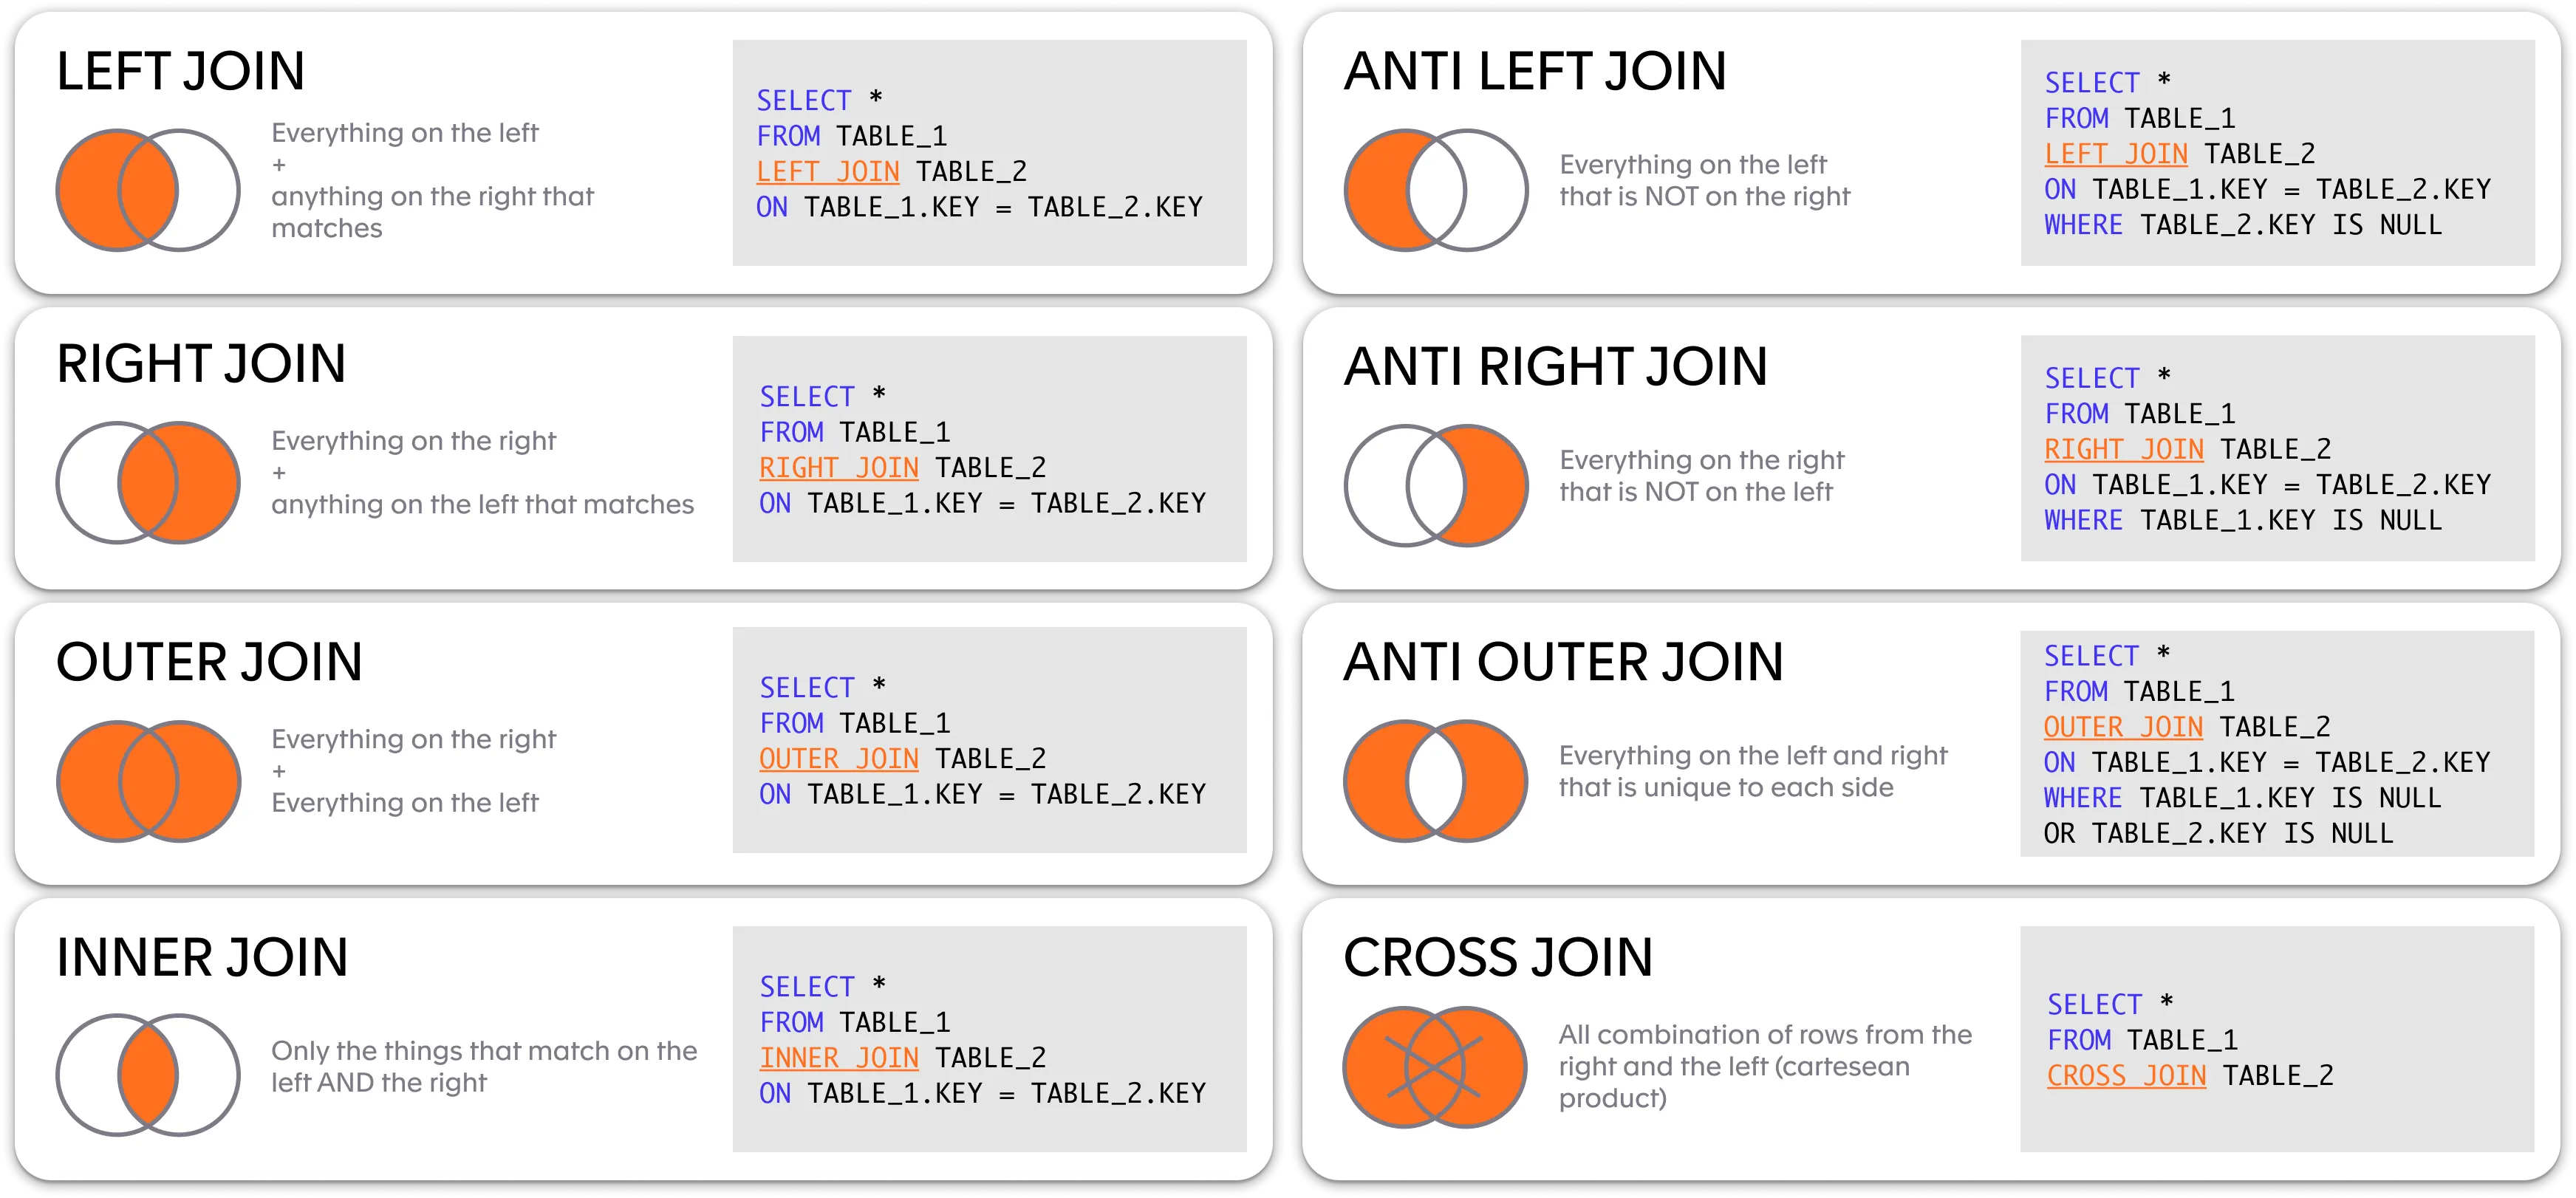

[Web con explicación de todos los joins](https://medium.com/@anant30/spark-joins-for-dummies-e9a05020f504)

<a id='drop-duplicates'></a>
## Drop Duplicates

Existen dos formas sencillas de eliminar duplicados en un DataFrame.
Ya hemos visto el uso de `distinct` en la sección *Get Distinct Rows*.
Ahora veremos cómo utilizar la función `dropDuplicates()` para conseguir el mismo resultado.

`drop_duplicates()` es un alias de `dropDuplicates()`.


In [74]:
from pyspark.sql import Row
from pyspark.sql import Row
mylist = [
  {"name":'Alice',"age":5,"height":80},
  {"name":'Jacob',"age":24,"height":80},
  {"name":'Alice',"age":5,"height":80}
]
df = spark.createDataFrame(Row(**x) for x in mylist)
df.dropDuplicates().show()

+-----+---+------+
| name|age|height|
+-----+---+------+
|Alice|  5|    80|
|Jacob| 24|    80|
+-----+---+------+



`dropDuplicates()` también puede recibir un parámetro opcional llamado *subset*,
que permite especificar las columnas sobre las que se debe realizar la comprobación de duplicados.


In [75]:
df.dropDuplicates(subset=['height']).show()

+-----+---+------+
| name|age|height|
+-----+---+------+
|Alice|  5|    80|
+-----+---+------+



Intenta incorporar estas prácticas a tu forma de programar para mejorar el rendimiento:

1. No utilices `NOT IN`, usa `NOT EXISTS`.
2. Evita `count` y `countDistinct` (utiliza `approxCountDistinct`).
3. Elimina duplicados lo antes posible.
4. Prioriza siempre las funciones SQL frente a `PandasUDF`.
